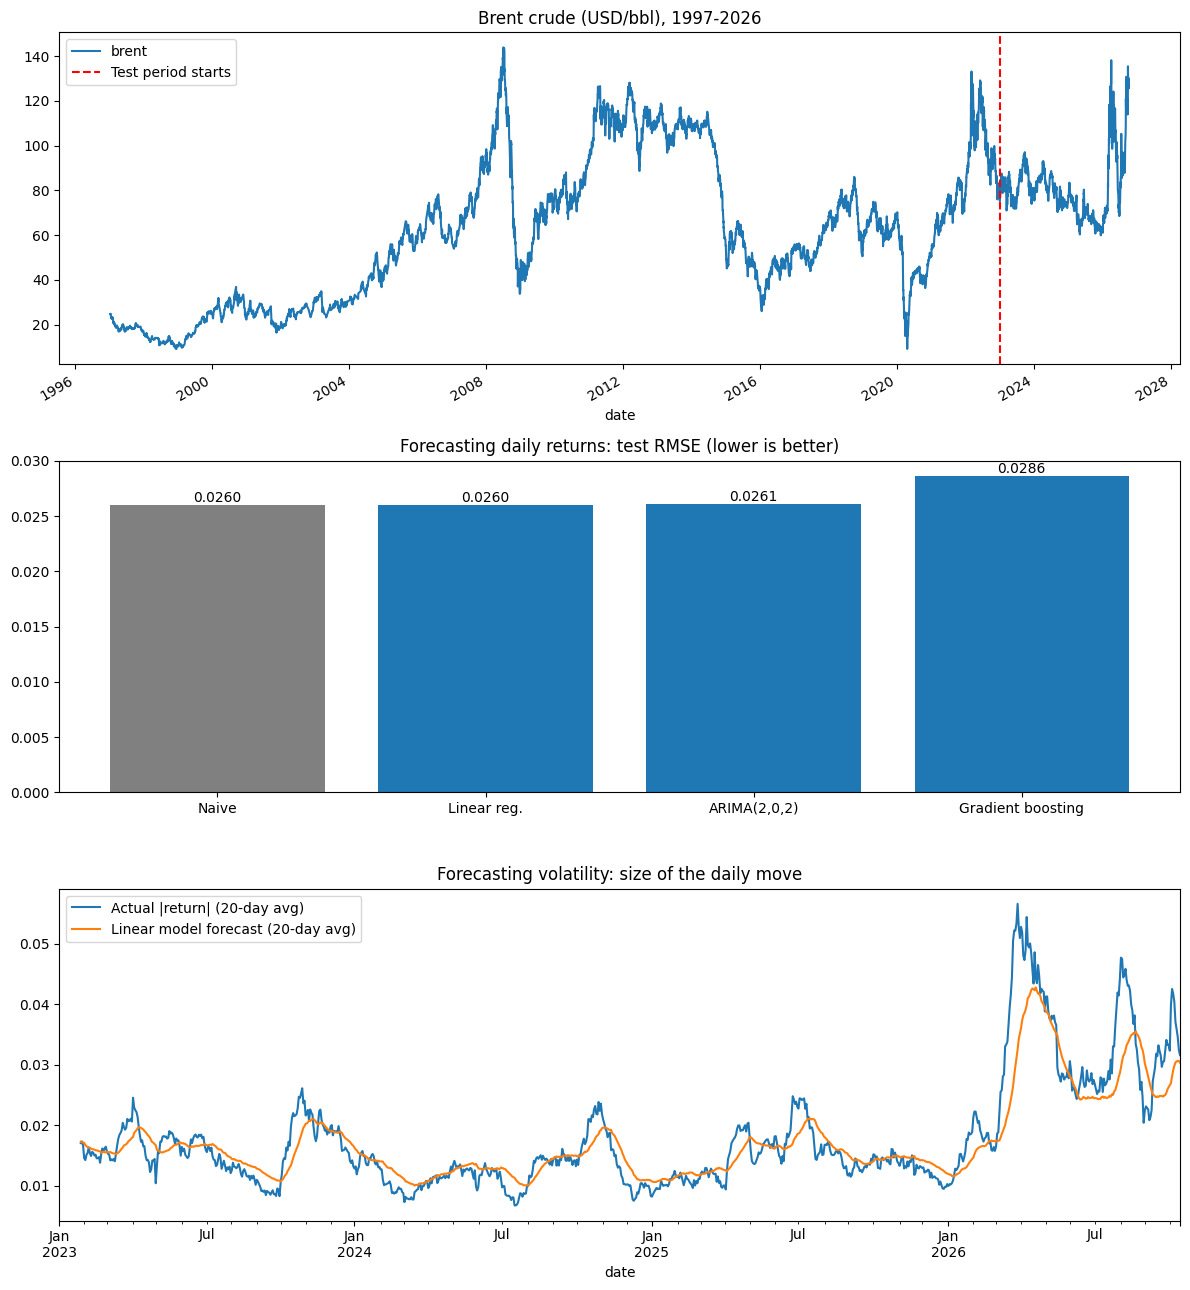

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(3, 1, figsize=(12, 13))

# 1) Brent price with the train/test split marked
data["brent"].plot(ax=ax[0], title="Brent crude (USD/bbl), 1997-2026")
ax[0].axvline(pd.Timestamp("2023-01-01"), color="red", linestyle="--", label="Test period starts")
ax[0].legend()

# 2) Returns forecasting: error by model
names = ["Naive", "Linear reg.", "ARIMA(2,0,2)", "Gradient boosting"]
rm = lambda p: np.sqrt(mean_squared_error(test, p))
vals = [rm(np.zeros(len(test))), rm(lin.predict(X_test)), rm(pred_arima), rm(gbr.predict(X_test))]
bars = ax[1].bar(names, vals, color=["grey", "tab:blue", "tab:blue", "tab:blue"])
ax[1].bar_label(bars, fmt="%.4f")
ax[1].set_title("Forecasting daily returns: test RMSE (lower is better)")

# 3) Volatility forecast vs actual (20-day averages for readability)
pred_v = pd.Series(vlin.predict(VX_test), index=VX_test.index)
vy_test.rolling(20).mean().plot(ax=ax[2], label="Actual |return| (20-day avg)")
pred_v.rolling(20).mean().plot(ax=ax[2], label="Linear model forecast (20-day avg)")
ax[2].set_title("Forecasting volatility: size of the daily move")
ax[2].legend()

plt.tight_layout()
plt.show()

In [2]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.tsa.arima.model import ARIMA

# ---------- load and clean ----------
series = {"brent": "DCOILBRENTEU", "gas": "DHHNGSP"}
frames = []
for name, sid in series.items():
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}"
    df = pd.read_csv(url, na_values=".")
    df = df.rename(columns={df.columns[0]: "date", sid: name})
    frames.append(df.set_index("date"))
data = pd.concat(frames, axis=1)
data.index = pd.to_datetime(data.index)
data = data.loc[data["gas"].first_valid_index():]
data = data.ffill(limit=3).dropna()
log_ret = np.log(data).diff().dropna()

# ---------- train/test split ----------
y = log_ret["brent"]
train = y[:"2022-12-31"]
test = y["2023-01-01":]
print("train days:", len(train), " test days:", len(test))

def report(name, pred):
    pred = np.asarray(pred)
    rmse = np.sqrt(mean_squared_error(test, pred))
    mae = mean_absolute_error(test, pred)
    hit = np.nan if np.all(pred == 0) else (np.sign(pred) == np.sign(test.values)).mean()
    print(f"{name:<22} RMSE={rmse:.5f}  MAE={mae:.5f}  directional accuracy={hit:.3f}")

print("\n--- Forecasting returns ---")
report("Naive (zero return)", np.zeros(len(test)))

feat = pd.DataFrame(index=log_ret.index)
for k in range(1, 6):
    feat[f"brent_lag{k}"] = log_ret["brent"].shift(k)
feat["gas_lag1"] = log_ret["gas"].clip(-0.3, 0.3).shift(1)
feat["vol_5"] = log_ret["brent"].abs().rolling(5).mean().shift(1)
feat["vol_20"] = log_ret["brent"].abs().rolling(20).mean().shift(1)
feat = feat.dropna()
target = log_ret["brent"].loc[feat.index]
X_train, y_train = feat[:"2022-12-31"], target[:"2022-12-31"]
X_test = feat["2023-01-01":]
assert X_test.index.equals(test.index)

lin = LinearRegression().fit(X_train, y_train)
report("Linear regression", lin.predict(X_test))

arima = ARIMA(train.values, order=(2, 0, 2)).fit()
pred_arima = arima.append(test.values, refit=False).get_prediction(start=len(train)).predicted_mean
report("ARIMA (2,0,2)", pred_arima)

gbr = GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05,
                                subsample=0.8, random_state=0).fit(X_train, y_train)
report("Gradient boosting", gbr.predict(X_test))

# ---------- forecasting volatility ----------
print("\n--- Forecasting volatility (size of tomorrow's move) ---")
absr = log_ret["brent"].abs()
vf = pd.DataFrame(index=log_ret.index)
vf["abs_lag1"] = absr.shift(1)
vf["abs_5"] = absr.rolling(5).mean().shift(1)
vf["abs_20"] = absr.rolling(20).mean().shift(1)
vf["abs_60"] = absr.rolling(60).mean().shift(1)
vf["gas_abs_lag1"] = log_ret["gas"].abs().clip(upper=0.3).shift(1)
vf = vf.dropna()
vy = absr.loc[vf.index]
VX_train, vy_train = vf[:"2022-12-31"], vy[:"2022-12-31"]
VX_test, vy_test = vf["2023-01-01":], vy["2023-01-01":]

def vreport(name, pred):
    pred = np.asarray(pred)
    rmse = np.sqrt(mean_squared_error(vy_test, pred))
    mae = mean_absolute_error(vy_test, pred)
    r2 = r2_score(vy_test, pred)
    print(f"{name:<24} RMSE={rmse:.5f}  MAE={mae:.5f}  R2={r2:.3f}")

vreport("Training mean", np.full(len(vy_test), vy_train.mean()))
vreport("Yesterday's |return|", VX_test["abs_lag1"])
vreport("20-day average", VX_test["abs_20"])
vlin = LinearRegression().fit(VX_train, vy_train)
vreport("Linear regression", vlin.predict(VX_test))
vgbr = GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05,
                                 subsample=0.8, random_state=0).fit(VX_train, vy_train)
vreport("Gradient boosting", vgbr.predict(VX_test))

train days: 5949  test days: 988

--- Forecasting returns ---
Naive (zero return)    RMSE=0.02600  MAE=0.01782  directional accuracy=nan
Linear regression      RMSE=0.02603  MAE=0.01791  directional accuracy=0.472
ARIMA (2,0,2)          RMSE=0.02607  MAE=0.01786  directional accuracy=0.484
Gradient boosting      RMSE=0.02860  MAE=0.01832  directional accuracy=0.484

--- Forecasting volatility (size of tomorrow's move) ---
Training mean            RMSE=0.01896  MAE=0.01259  R2=-0.002
Yesterday's |return|     RMSE=0.02378  MAE=0.01611  R2=-0.577
20-day average           RMSE=0.01775  MAE=0.01207  R2=0.122
Linear regression        RMSE=0.01760  MAE=0.01193  R2=0.136
Gradient boosting        RMSE=0.01964  MAE=0.01209  R2=-0.076
